# EDA Dataset A — Deteksi Pencemaran Limbah pada Sungai
**Proyek:** Deteksi Pencemaran Limbah pada Sungai Berbasis IoT dan Artificial Intelligence

Notebook ini melanjutkan audit dan pemilihan dataset dengan menganalisis Dataset A, `fishpond_dataset_multiclass_2153.csv`. Setiap tahap berisi deskripsi, output, dan kesimpulan.

**Google Colab:** jalankan cell berurutan dan unggah file CSV saat diminta. Tabel dan grafik tampil langsung di output cell. Notebook tidak menyimpan hasil analisis atau salinan dataset ke file lokal.

**Batasan:** Dataset A berasal dari konteks kolam ikan (*fishpond*), bukan pengukuran sungai yang telah divalidasi. Hasil eksperimen tidak otomatis membuktikan kinerja pada sungai nyata.

## Persiapan — Import library
Memuat pustaka analisis tabel, numerik, dan visualisasi. Tidak ada file hasil analisis yang ditulis.

In [ ]:
import io, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (10, 5)
print("Library siap digunakan.")

Library siap digunakan.


## Tahap 1 — Memuat dan Memahami Dataset

Memuat CSV, memeriksa dimensi, kolom, tipe data, dan contoh baris. Target eksperimen adalah `class`.

In [ ]:
from google.colab import files
uploaded=files.upload()
expected="fishpond_dataset_multiclass_2153.csv"
csvs=[n for n in uploaded if n.lower().endswith(".csv")]
if expected in uploaded: fname=expected
elif len(csvs)==1: fname=csvs[0]; print("Menggunakan file:",fname)
else: raise ValueError(f"Unggah satu CSV bernama {expected}. CSV ditemukan: {csvs}")
df=pd.read_csv(io.BytesIO(uploaded[fname])); TARGET="class"
display(df.head()); print("Ukuran:",df.shape)
display(pd.DataFrame({"Tipe data":df.dtypes.astype(str),"Nilai terisi":df.notna().sum()}))
if TARGET not in df.columns: raise ValueError(f"Target {TARGET!r} tidak ditemukan.")
print("\nKESIMPULAN TAHAP 1:",f"Dataset berisi {len(df):,} baris dan {df.shape[1]} kolom; target tersedia.")

Saving fishpond_dataset_multiclass_2153.csv to fishpond_dataset_multiclass_2153.csv


,sample_id,timestamp,orp_mV,ec_uScm,tds_mgL,turbidity_NTU,temp_C,pH,do_mgL,class
0,1507,2026-01-06 05:30:00,594.66,19.14,6.07,130.13,21.86,9.35,11.69,Warning
1,1768,2026-01-07 03:15:00,593.54,1831.09,1017.97,52.15,20.17,9.32,2.33,Warning
2,890,2026-01-04 02:05:00,495.26,40.52,29.74,35.69,30.10,6.49,9.09,Caution
3,307,2026-01-02 01:30:00,281.85,442.84,221.24,17.30,25.51,7.71,6.09,Normal
4,1774,2026-01-07 03:45:00,510.28,1790.43,859.00,132.55,32.56,5.62,2.82,Warning


Ukuran: (2153, 10)


,Tipe data,Nilai terisi
sample_id,int64,2153
timestamp,object,2153
orp_mV,float64,2153
ec_uScm,float64,2153
tds_mgL,float64,2153
turbidity_NTU,float64,2153
temp_C,float64,2153
pH,float64,2153
do_mgL,float64,2153
class,object,2153



KESIMPULAN TAHAP 1: Dataset berisi 2,153 baris dan 10 kolom; target tersedia.


## Tahap 2 — Analisis Missing Value

Menghitung jumlah dan persentase nilai kosong per kolom. Tahap ini tetap dicatat meskipun tidak ada nilai kosong.

In [ ]:
missing=pd.DataFrame({"Jumlah Missing":df.isna().sum(),"Persentase (%)":(df.isna().mean()*100).round(2)})
display(missing); total=int(df.isna().sum().sum())
print("\nKESIMPULAN TAHAP 2:",f"Ditemukan {total} nilai kosong." if total else "Tidak ditemukan missing value; imputasi nilai kosong yang terdeteksi tidak diperlukan.")

,Jumlah Missing,Persentase (%)
sample_id,0,0.0
timestamp,0,0.0
orp_mV,0,0.0
ec_uScm,0,0.0
tds_mgL,0,0.0
turbidity_NTU,0,0.0
temp_C,0,0.0
pH,0,0.0
do_mgL,0,0.0
class,0,0.0



KESIMPULAN TAHAP 2: Tidak ditemukan missing value; imputasi nilai kosong yang terdeteksi tidak diperlukan.


## Tahap 3 — Analisis Duplikasi

Memeriksa duplikasi baris penuh dan nilai berulang pada kolom identitas bila tersedia.

In [ ]:
dups=int(df.duplicated().sum()); print("Baris duplikat penuh:",dups)
ids=[c for c in df.columns if c.lower() in {"sample_id","id","record_id"}]
for c in ids: print(f"{c}: {df[c].nunique(dropna=True)} nilai unik; {int(df[c].duplicated().sum())} kemunculan berulang setelah yang pertama.")
print("\nKESIMPULAN TAHAP 3:","Tidak ditemukan baris duplikat penuh." if dups==0 else f"Ada {dups} baris duplikat; tinjau sebelum memutuskan penghapusan.")

Baris duplikat penuh: 0
sample_id: 2153 nilai unik; 0 kemunculan berulang setelah yang pertama.

KESIMPULAN TAHAP 3: Tidak ditemukan baris duplikat penuh.


## Tahap 4 — Validasi Tipe Data dan Nilai

Memeriksa tipe data, nilai tak hingga, nilai negatif, dan kemampuan membaca timestamp. Nilai negatif ditandai, bukan otomatis dianggap salah.

In [ ]:
num=df.select_dtypes(include=np.number).columns.tolist(); display(df.dtypes.astype(str).rename("Tipe data").to_frame())
if num:
 vals=df[num].to_numpy(dtype=float)
 display(pd.DataFrame({"Nilai tak hingga":np.isinf(vals).sum(axis=0),"Nilai negatif":(df[num]<0).sum()},index=num))
if "timestamp" in df:
 ts=pd.to_datetime(df["timestamp"],errors="coerce"); print("Timestamp valid:",int(ts.notna().sum()),"/",len(df),"| gagal:",int(ts.isna().sum()))
print("\nKESIMPULAN TAHAP 4: Tinjau nilai negatif atau ekstrem sesuai karakteristik parameter dan dokumentasi sumber.")

,Tipe data
sample_id,int64
timestamp,object
orp_mV,float64
ec_uScm,float64
tds_mgL,float64
turbidity_NTU,float64
temp_C,float64
pH,float64
do_mgL,float64
class,object


,Nilai tak hingga,Nilai negatif
sample_id,0,0
orp_mV,0,301
ec_uScm,0,0
tds_mgL,0,0
turbidity_NTU,0,0
temp_C,0,0
pH,0,0
do_mgL,0,0


Timestamp valid: 2153 / 2153 | gagal: 0

KESIMPULAN TAHAP 4: Tinjau nilai negatif atau ekstrem sesuai karakteristik parameter dan dokumentasi sumber.


## Tahap 5 — Statistik Deskriptif

Meringkas rata-rata, standar deviasi, minimum, kuartil, median, dan maksimum. Kolom ID bukan parameter kualitas air.

In [ ]:
num=df.select_dtypes(include=np.number).columns.tolist()
features=[c for c in num if c.lower() not in {"sample_id","id","record_id"} and c!=TARGET]
display(df[num].describe().T.round(3))
print("\nKESIMPULAN TAHAP 5:",f"Statistik dihitung untuk {len(num)} kolom numerik dan {len(features)} kandidat fitur non-ID.")
print("Statistik membantu memahami skala data, bukan menentukan sendiri apakah air aman atau tercemar.")

,count,mean,std,min,25%,50%,75%,max
sample_id,2153.0,1077.000,621.662,1.00,539.00,1077.00,1615.00,2153.00
orp_mV,2153.0,291.254,261.019,-249.60,85.45,287.24,471.09,898.88
ec_uScm,2153.0,655.756,1025.007,1.04,30.06,244.55,783.26,4965.58
tds_mgL,2153.0,359.809,563.782,0.00,16.67,127.57,422.40,3267.23
turbidity_NTU,2153.0,101.353,138.438,1.02,21.41,41.48,113.93,598.68
temp_C,2153.0,27.437,5.193,15.00,23.85,27.53,31.41,37.99
pH,2153.0,7.556,1.543,4.51,6.21,7.57,8.89,10.50
do_mgL,2153.0,7.088,3.601,0.52,4.32,6.94,9.58,15.98



KESIMPULAN TAHAP 5: Statistik dihitung untuk 8 kolom numerik dan 7 kandidat fitur non-ID.
Statistik membantu memahami skala data, bukan menentukan sendiri apakah air aman atau tercemar.


## Tahap 6 — Distribusi Kelas Target

Menghitung jumlah dan persentase setiap kelas `class` serta memvisualisasikan keseimbangan kelas.

,Jumlah,Persentase (%)
class,,
Caution,670,31.12
Normal,638,29.63
Warning,478,22.20
Severe,367,17.05


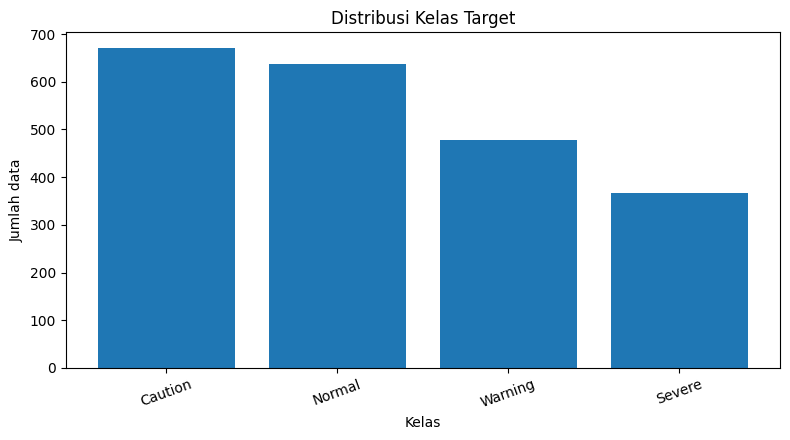


KESIMPULAN TAHAP 6: Terdapat 4 kelas teramati. Evaluasi model perlu memeriksa precision, recall, dan F1-score per kelas.


In [ ]:
counts=df[TARGET].value_counts(dropna=False)
display(pd.DataFrame({"Jumlah":counts,"Persentase (%)":(df[TARGET].value_counts(dropna=False,normalize=True)*100).round(2)}))
plt.figure(figsize=(8,4.5)); plt.bar(counts.index.astype(str),counts.values); plt.title("Distribusi Kelas Target"); plt.xlabel("Kelas"); plt.ylabel("Jumlah data"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()
print("\nKESIMPULAN TAHAP 6:",f"Terdapat {df[TARGET].nunique(dropna=True)} kelas teramati. Evaluasi model perlu memeriksa precision, recall, dan F1-score per kelas.")

## Tahap 7 — Distribusi Fitur Numerik

Histogram digunakan untuk melihat bentuk distribusi, rentang, kemencengan, dan kemungkinan kelompok nilai fitur non-ID.

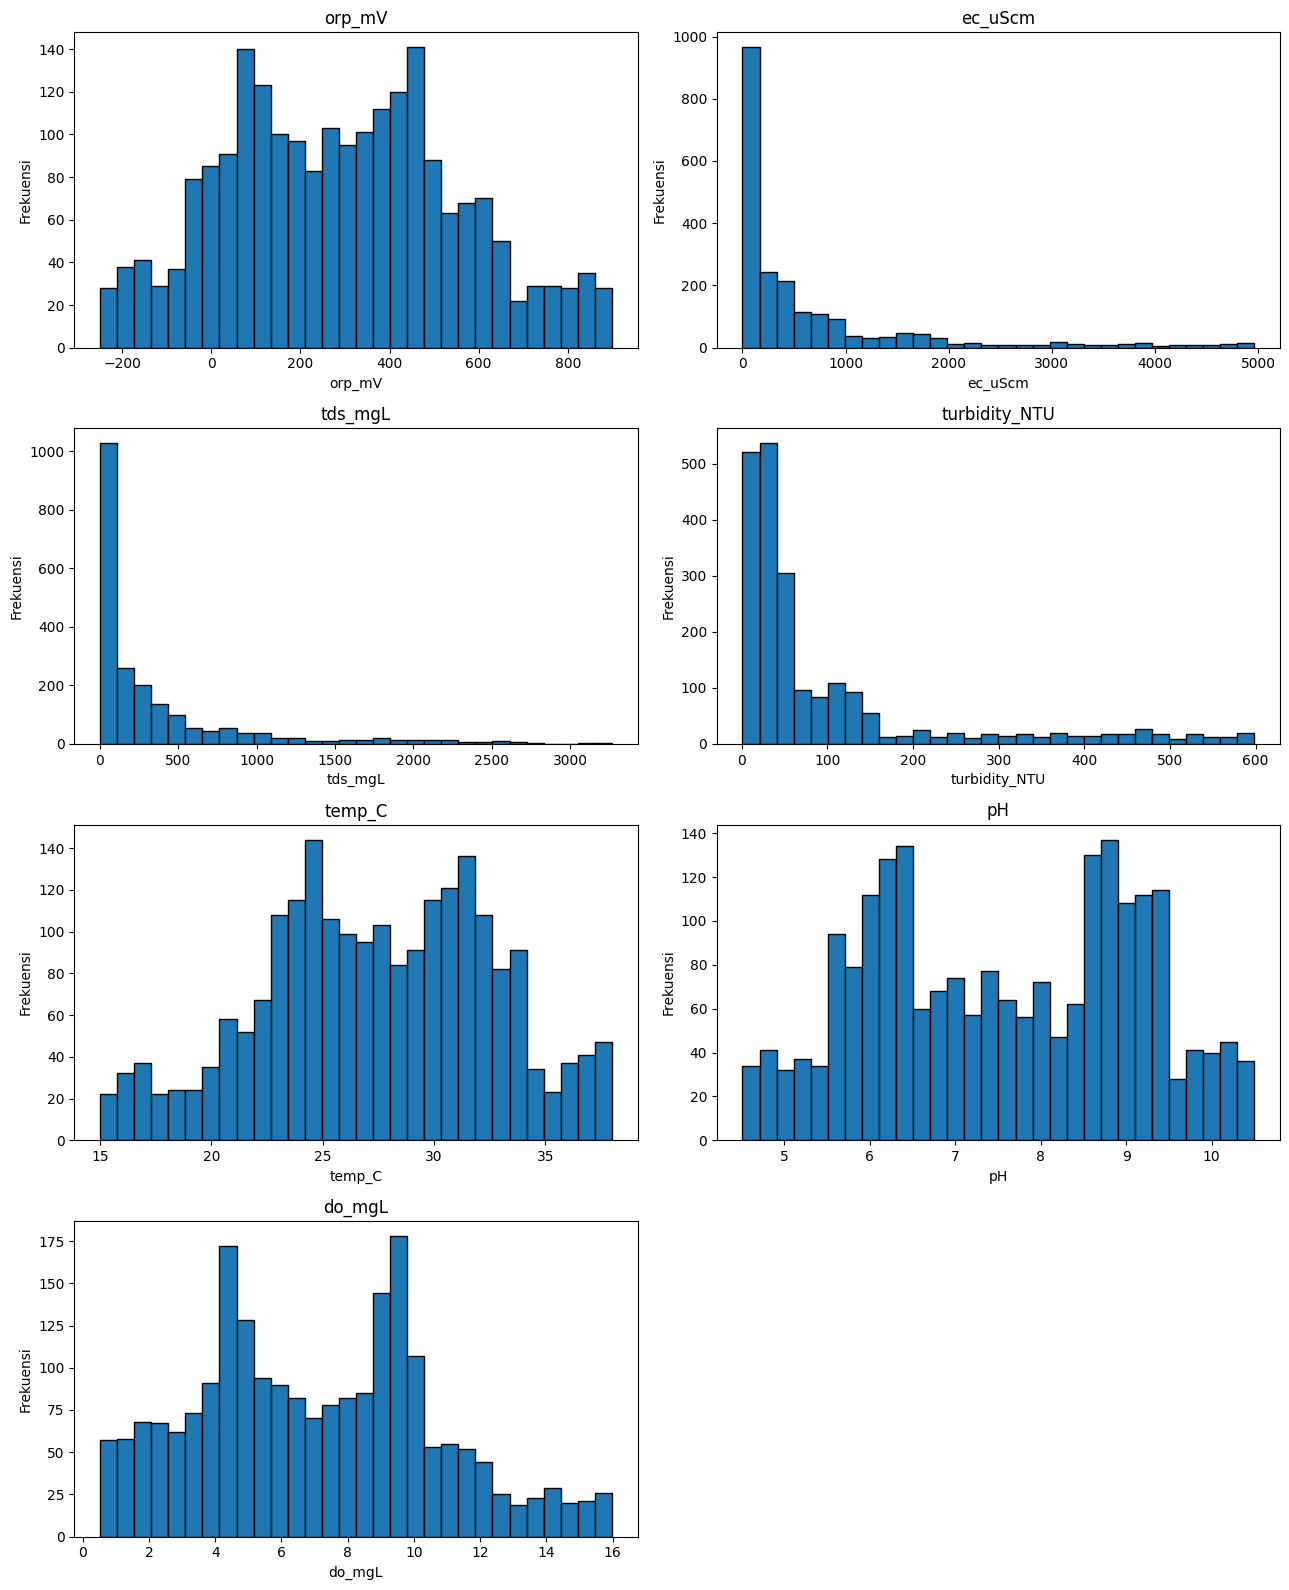


KESIMPULAN TAHAP 7: Histogram ditampilkan untuk 7 fitur. Transformasi preprocessing dipilih berdasarkan temuan, bukan otomatis untuk semua fitur.


In [ ]:
if features:
 ncol=2; nrow=int(np.ceil(len(features)/ncol)); fig,axes=plt.subplots(nrow,ncol,figsize=(13,4*nrow)); axes=np.array(axes).reshape(-1)
 for ax,c in zip(axes,features): ax.hist(pd.to_numeric(df[c],errors="coerce").dropna(),bins=30,edgecolor="black"); ax.set_title(c); ax.set_xlabel(c); ax.set_ylabel("Frekuensi")
 for ax in axes[len(features):]: ax.axis("off")
 plt.tight_layout(); plt.show()
print("\nKESIMPULAN TAHAP 7:",f"Histogram ditampilkan untuk {len(features)} fitur. Transformasi preprocessing dipilih berdasarkan temuan, bukan otomatis untuk semua fitur.")

## Tahap 8 — Analisis Outlier

Mengidentifikasi kandidat nilai ekstrem dengan IQR dan boxplot. Outlier tidak langsung dihapus karena dapat mencerminkan kondisi penting.

,Batas bawah,Batas atas,Jumlah kandidat outlier,Persentase (%)
Fitur,,,,
orp_mV,-493.010,1049.550,0,0.000
ec_uScm,-1099.740,1913.060,205,9.522
tds_mgL,-591.925,1030.995,214,9.940
turbidity_NTU,-117.370,252.710,280,13.005
temp_C,12.510,42.750,0,0.000
pH,2.190,12.910,0,0.000
do_mgL,-3.570,17.470,0,0.000


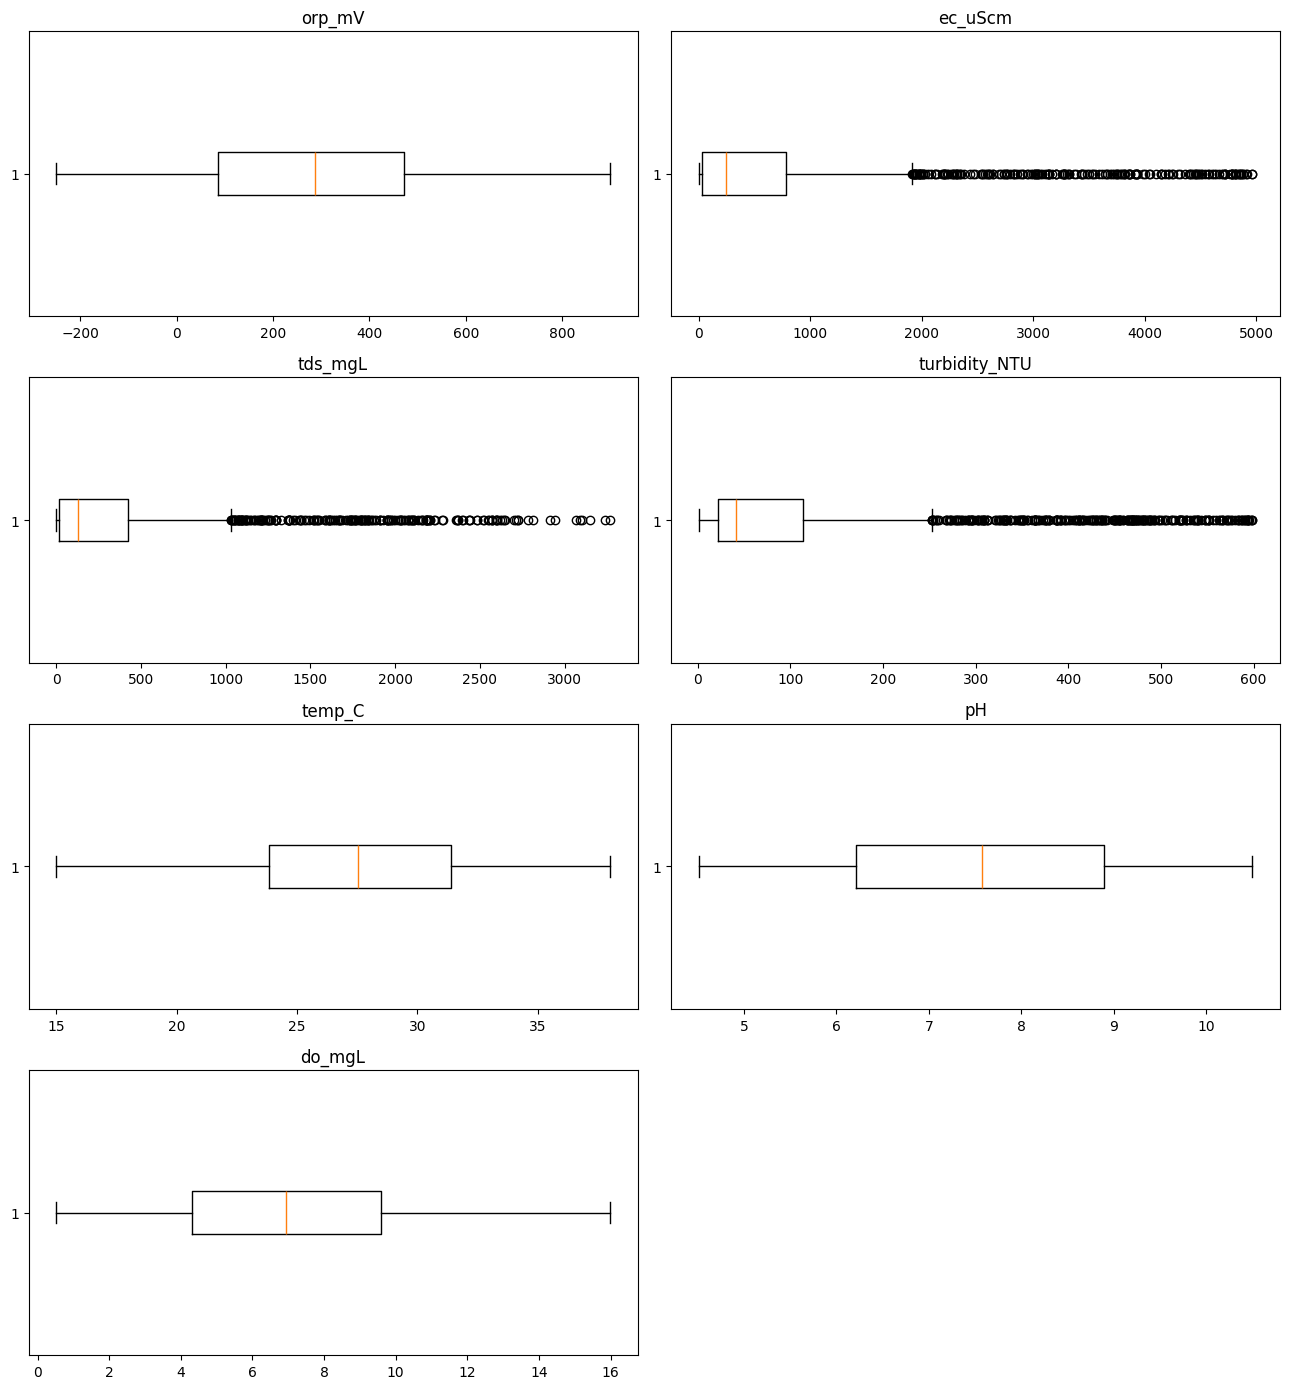


KESIMPULAN TAHAP 8: Kandidat outlier pada semua fitur: 699 . Tinjau konteks sebelum menghapus.


In [ ]:
rows=[]
for c in features:
 x=pd.to_numeric(df[c],errors="coerce").dropna()
 if x.empty: continue
 q1,q3=x.quantile([.25,.75]); iqr=q3-q1; lo=q1-1.5*iqr; hi=q3+1.5*iqr; n=int(((x<lo)|(x>hi)).sum())
 rows.append({"Fitur":c,"Batas bawah":lo,"Batas atas":hi,"Jumlah kandidat outlier":n,"Persentase (%)":100*n/len(x)})
out=pd.DataFrame(rows).set_index("Fitur") if rows else pd.DataFrame(); display(out.round(3))
if features:
 ncol=2; nrow=int(np.ceil(len(features)/ncol)); fig,axes=plt.subplots(nrow,ncol,figsize=(13,3.5*nrow)); axes=np.array(axes).reshape(-1)
 for ax,c in zip(axes,features): ax.boxplot(pd.to_numeric(df[c],errors="coerce").dropna(),vert=False); ax.set_title(c)
 for ax in axes[len(features):]: ax.axis("off")
 plt.tight_layout(); plt.show()
print("\nKESIMPULAN TAHAP 8: Kandidat outlier pada semua fitur:",int(out["Jumlah kandidat outlier"].sum()) if not out.empty else 0,". Tinjau konteks sebelum menghapus.")

## Tahap 9 — Hubungan Fitur dengan Kelas

Membandingkan median dan distribusi fitur per kelas. Perbedaan visual tidak membuktikan sebab-akibat atau kinerja pada data baru.

,orp_mV,ec_uScm,tds_mgL,turbidity_NTU,temp_C,pH,do_mgL
class,,,,,,,
Caution,274.985,48.140,30.370,37.615,24.97,8.505,9.06
Normal,278.655,265.830,141.895,13.145,27.48,7.450,6.91
Severe,652.370,2030.260,980.940,376.280,34.08,9.570,12.07
Warning,514.005,19.395,16.560,102.420,32.08,9.070,3.85


/tmp/ipykernel_976/3654111443.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.figure(figsize=(8,4)); plt.boxplot(data,labels=labels); plt.title(f"{c} berdasarkan kelas"); plt.xlabel("Kelas"); plt.ylabel(c); plt.tight_layout(); plt.show()


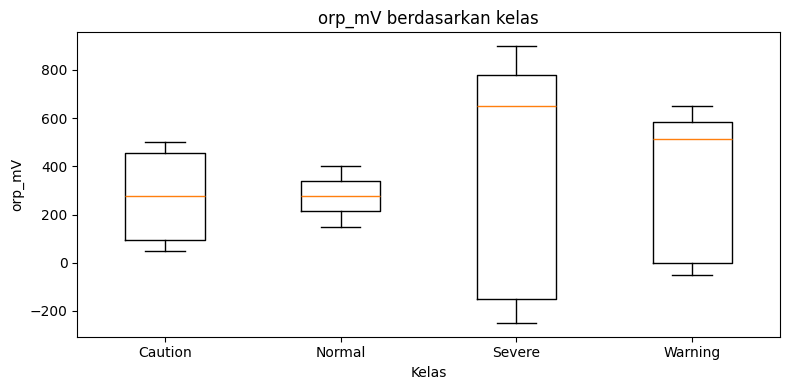

/tmp/ipykernel_976/3654111443.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.figure(figsize=(8,4)); plt.boxplot(data,labels=labels); plt.title(f"{c} berdasarkan kelas"); plt.xlabel("Kelas"); plt.ylabel(c); plt.tight_layout(); plt.show()


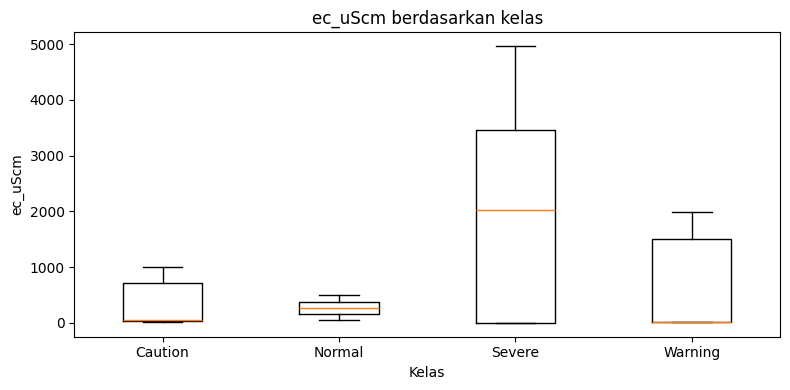

/tmp/ipykernel_976/3654111443.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.figure(figsize=(8,4)); plt.boxplot(data,labels=labels); plt.title(f"{c} berdasarkan kelas"); plt.xlabel("Kelas"); plt.ylabel(c); plt.tight_layout(); plt.show()


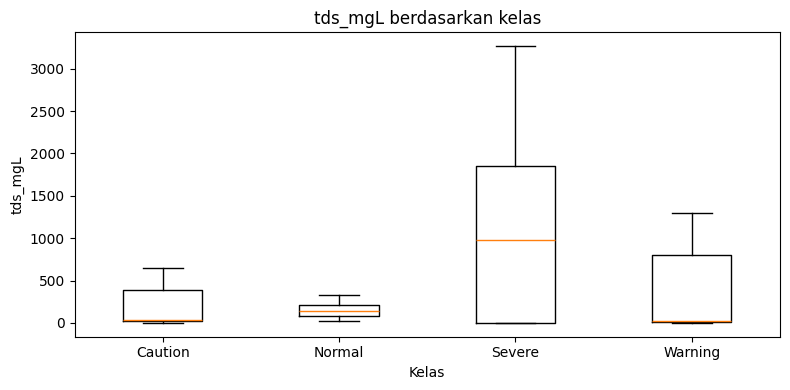

/tmp/ipykernel_976/3654111443.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.figure(figsize=(8,4)); plt.boxplot(data,labels=labels); plt.title(f"{c} berdasarkan kelas"); plt.xlabel("Kelas"); plt.ylabel(c); plt.tight_layout(); plt.show()


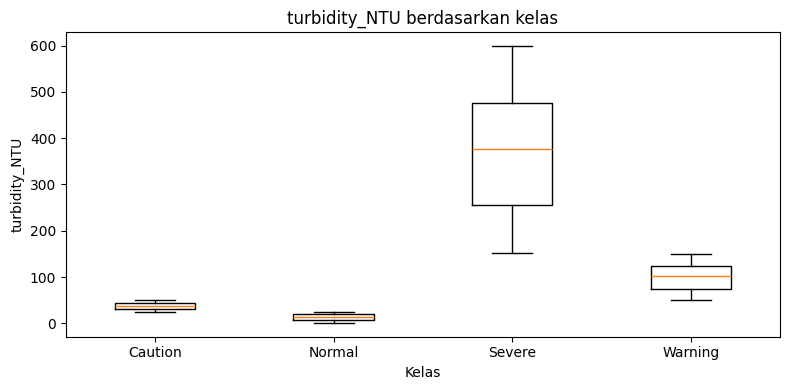

/tmp/ipykernel_976/3654111443.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.figure(figsize=(8,4)); plt.boxplot(data,labels=labels); plt.title(f"{c} berdasarkan kelas"); plt.xlabel("Kelas"); plt.ylabel(c); plt.tight_layout(); plt.show()


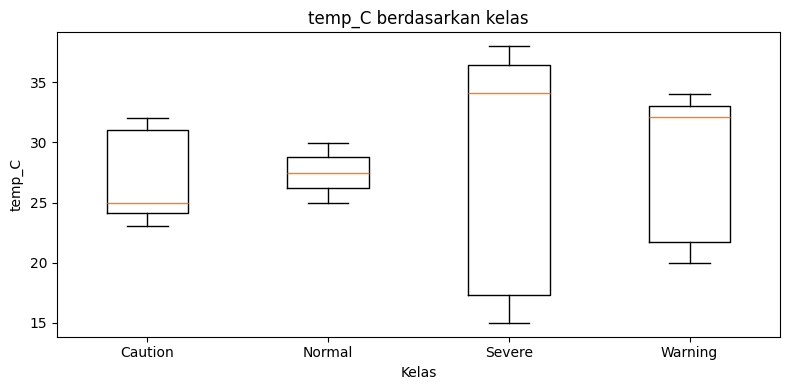

/tmp/ipykernel_976/3654111443.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.figure(figsize=(8,4)); plt.boxplot(data,labels=labels); plt.title(f"{c} berdasarkan kelas"); plt.xlabel("Kelas"); plt.ylabel(c); plt.tight_layout(); plt.show()


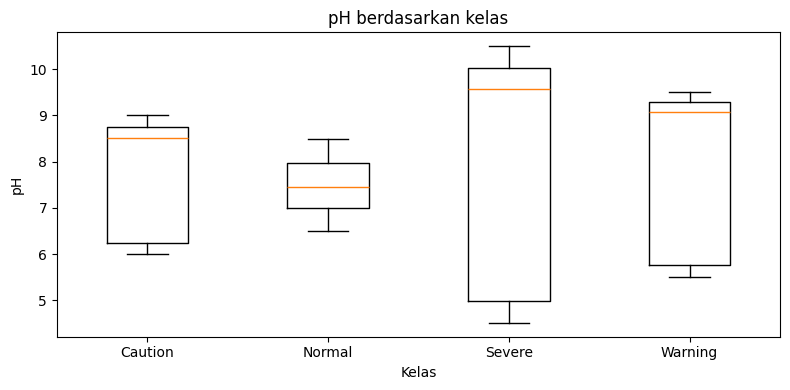

/tmp/ipykernel_976/3654111443.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.figure(figsize=(8,4)); plt.boxplot(data,labels=labels); plt.title(f"{c} berdasarkan kelas"); plt.xlabel("Kelas"); plt.ylabel(c); plt.tight_layout(); plt.show()


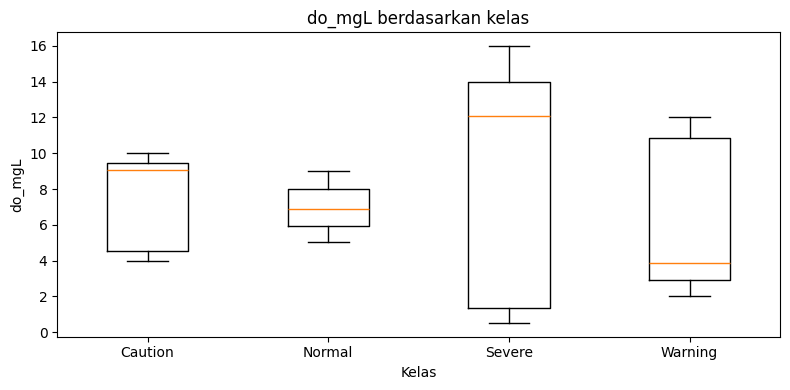


KESIMPULAN TAHAP 9: Periksa fitur yang memisahkan kelas sangat kuat; pola ini mungkin terkait aturan pembentukan label.


In [ ]:
display(df.groupby(TARGET,dropna=False)[features].median().round(3))
for c in features:
 data=[]; labels=[]
 for label,g in df.groupby(TARGET,dropna=False,sort=True):
  x=pd.to_numeric(g[c],errors="coerce").dropna()
  if len(x): data.append(x.to_numpy()); labels.append(str(label))
 if data:
  plt.figure(figsize=(8,4)); plt.boxplot(data,labels=labels); plt.title(f"{c} berdasarkan kelas"); plt.xlabel("Kelas"); plt.ylabel(c); plt.tight_layout(); plt.show()
print("\nKESIMPULAN TAHAP 9: Periksa fitur yang memisahkan kelas sangat kuat; pola ini mungkin terkait aturan pembentukan label.")

## Tahap 10 — Korelasi Antarfitur

Mengukur korelasi Pearson antarfitur numerik non-ID. Korelasi menunjukkan hubungan linear, bukan sebab-akibat.

,orp_mV,ec_uScm,tds_mgL,turbidity_NTU,temp_C,pH,do_mgL
orp_mV,1.000,0.039,0.041,0.073,0.045,0.007,0.027
ec_uScm,0.039,1.000,0.990,0.489,0.010,0.011,0.048
tds_mgL,0.041,0.990,1.000,0.485,0.005,0.008,0.043
turbidity_NTU,0.073,0.489,0.485,1.000,-0.007,0.002,0.066
temp_C,0.045,0.010,0.005,-0.007,1.000,-0.017,0.030
pH,0.007,0.011,0.008,0.002,-0.017,1.000,-0.043
do_mgL,0.027,0.048,0.043,0.066,0.030,-0.043,1.000


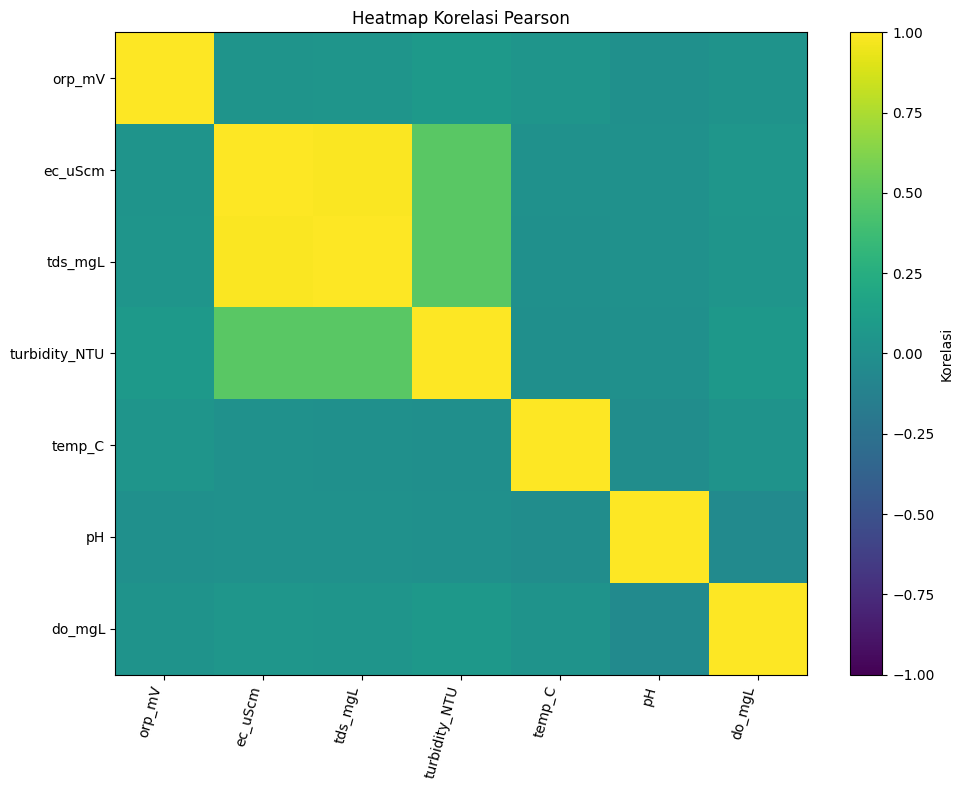

Pasangan korelasi absolut terbesar:
ec_uScm — tds_mgL: r=0.990
ec_uScm — turbidity_NTU: r=0.489
tds_mgL — turbidity_NTU: r=0.485
orp_mV — turbidity_NTU: r=0.073
turbidity_NTU — do_mgL: r=0.066

KESIMPULAN TAHAP 10: Gunakan korelasi sebagai petunjuk eksplorasi; jangan menghapus fitur hanya berdasarkan satu nilai korelasi.


In [ ]:
if len(features)>=2:
 corr=df[features].corr(); display(corr.round(3)); fig,ax=plt.subplots(figsize=(10,8)); im=ax.imshow(corr,vmin=-1,vmax=1,aspect="auto")
 ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns,rotation=75,ha="right"); ax.set_yticks(range(len(corr.index))); ax.set_yticklabels(corr.index); ax.set_title("Heatmap Korelasi Pearson"); fig.colorbar(im,ax=ax,label="Korelasi"); plt.tight_layout(); plt.show()
 pairs=sorted([(corr.iloc[i,j],corr.index[i],corr.columns[j]) for i in range(len(corr)) for j in range(i+1,len(corr))],key=lambda x:abs(x[0]),reverse=True)
 print("Pasangan korelasi absolut terbesar:"); [print(f"{a} — {b}: r={r:.3f}") for r,a,b in pairs[:5]]
else: print("Fitur numerik kurang dari dua; korelasi tidak dihitung.")
print("\nKESIMPULAN TAHAP 10: Gunakan korelasi sebagai petunjuk eksplorasi; jangan menghapus fitur hanya berdasarkan satu nilai korelasi.")

## Tahap 11 — Analisis Pola Waktu

Memeriksa validitas timestamp, rentang waktu, timestamp unik, interval, dan tren. Adanya timestamp tidak otomatis berarti data cukup untuk prediksi dua jam.

Timestamp valid: 2153 / 2153 | gagal: 0
Awal: 2026-01-01 00:00:00 | akhir: 2026-01-08 11:20:00 | unik: 2153


,count,mean,std,min,25%,50%,75%,max
Interval waktu,2152,0 days 00:05:00,0 days 00:00:00,0 days 00:05:00,0 days 00:05:00,0 days 00:05:00,0 days 00:05:00,0 days 00:05:00


Interval median: 0 days 00:05:00


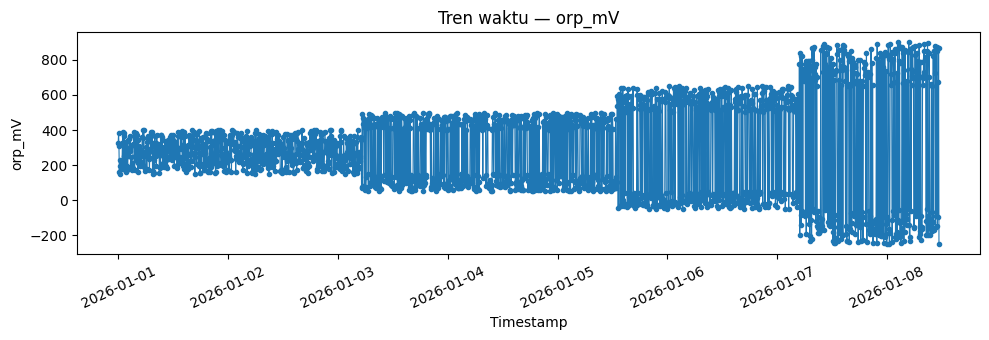

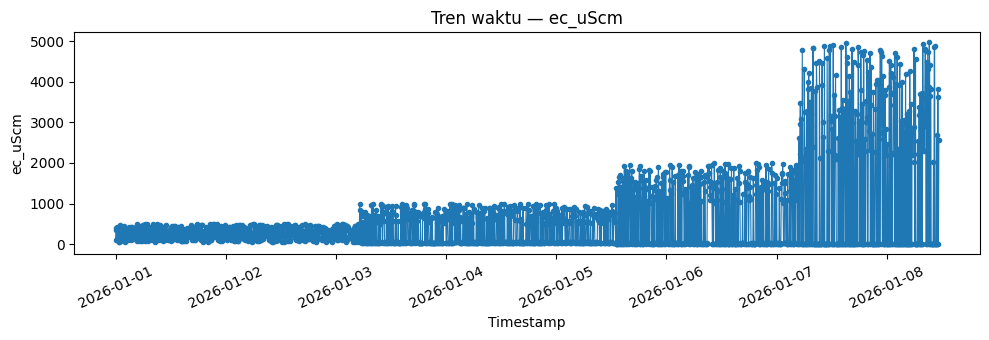

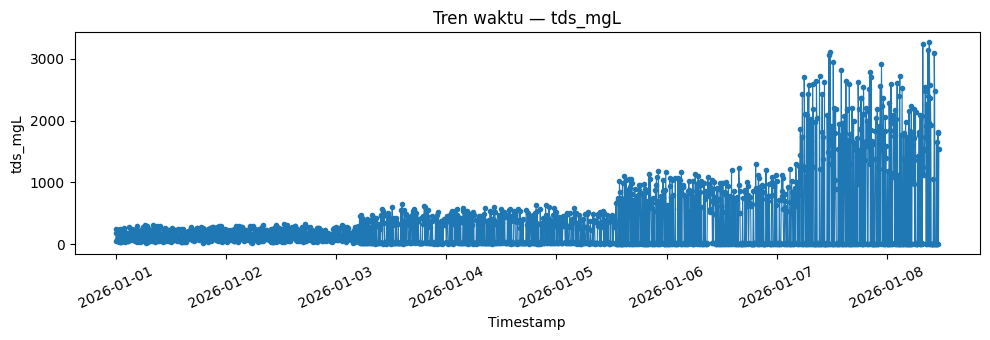

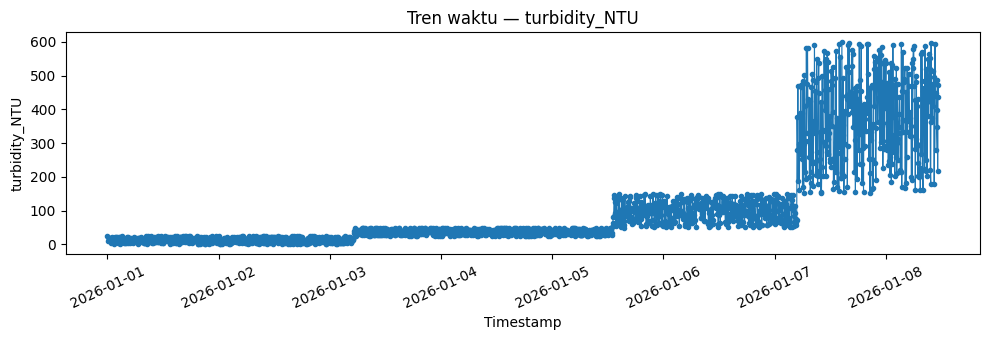


KESIMPULAN TAHAP 11: Periksa interval dan cakupan waktu sebelum merancang prediksi temporal; data yang tidak memadai tidak mendukung klaim prediksi dua jam.


In [ ]:
if "timestamp" not in df: print("Kolom timestamp tidak tersedia.")
else:
 temp=df.copy(); temp["_ts"]=pd.to_datetime(temp["timestamp"],errors="coerce"); ts=temp["_ts"].dropna()
 print("Timestamp valid:",len(ts),"/",len(df),"| gagal:",int(temp["_ts"].isna().sum()))
 if len(ts):
  print("Awal:",ts.min(),"| akhir:",ts.max(),"| unik:",ts.nunique()); delta=ts.sort_values().diff().dropna()
  if len(delta): display(delta.describe().to_frame("Interval waktu").T); print("Interval median:",delta.median())
  temp=temp.dropna(subset=["_ts"]).sort_values("_ts")
  for c in features[:4]:
   plt.figure(figsize=(10,3.5)); plt.plot(temp["_ts"],temp[c],marker=".",linewidth=.8); plt.title(f"Tren waktu — {c}"); plt.xlabel("Timestamp"); plt.ylabel(c); plt.xticks(rotation=25); plt.tight_layout(); plt.show()
print("\nKESIMPULAN TAHAP 11: Periksa interval dan cakupan waktu sebelum merancang prediksi temporal; data yang tidak memadai tidak mendukung klaim prediksi dua jam.")

## Tahap 12 — Risiko Data Leakage dan Ketergantungan Label

Memeriksa hubungan `turbidity_NTU` dengan `class`. Audit sebelumnya menunjukkan ambang turbidity yang diuji pada data yang sama dapat mereproduksi label; ini indikasi risiko, bukan bukti pasti asal label.

,count,min,median,mean,max
class,,,,,
Caution,670,25.01,37.615,37.534,49.98
Normal,638,1.02,13.145,13.266,24.96
Severe,367,151.26,376.280,372.628,598.68
Warning,478,50.01,102.420,100.097,149.97


/tmp/ipykernel_976/655731478.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.figure(figsize=(8,4.5)); plt.boxplot(vals,labels=labels); plt.title("Turbidity berdasarkan kelas"); plt.xlabel("Kelas"); plt.ylabel("Turbidity (NTU)"); plt.tight_layout(); plt.show()


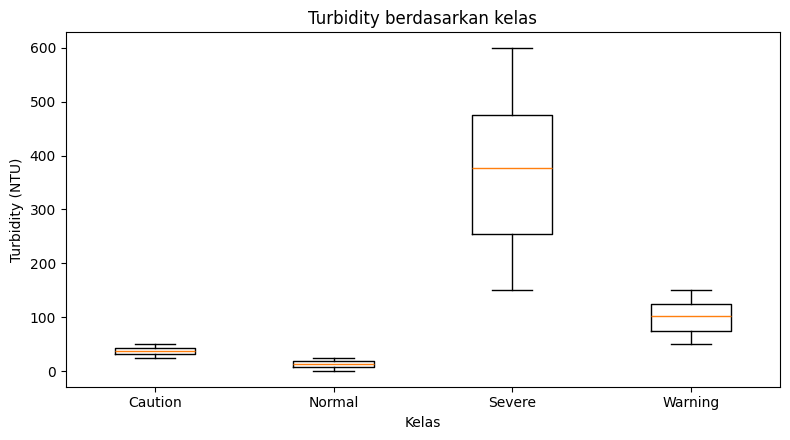


KESIMPULAN TAHAP 12
Jika kelas sangat terpisah berdasarkan turbidity, model berisiko hanya mempelajari aturan label tersebut.
Validasi dokumentasi label; pola statistik saja tidak membuktikan bagaimana label asli dibuat.


In [ ]:
if "turbidity_NTU" in df and TARGET in df:
 display(df.groupby(TARGET)["turbidity_NTU"].agg(["count","min","median","mean","max"]).round(3))
 vals=[]; labels=[]
 for label,g in df.groupby(TARGET,sort=True):
  x=g["turbidity_NTU"].dropna()
  if len(x): vals.append(x.to_numpy()); labels.append(str(label))
 plt.figure(figsize=(8,4.5)); plt.boxplot(vals,labels=labels); plt.title("Turbidity berdasarkan kelas"); plt.xlabel("Kelas"); plt.ylabel("Turbidity (NTU)"); plt.tight_layout(); plt.show()
else: print("Kolom turbidity_NTU atau class tidak ditemukan.")
print("\nKESIMPULAN TAHAP 12")
print("Jika kelas sangat terpisah berdasarkan turbidity, model berisiko hanya mempelajari aturan label tersebut.")
print("Validasi dokumentasi label; pola statistik saja tidak membuktikan bagaimana label asli dibuat.")

## Tahap 13 — Kesimpulan EDA dan Rekomendasi

Merangkum temuan kuantitatif dan menyusun tindakan sebelum preprocessing. Kesimpulan otomatis hanya berdasarkan hal yang dihitung dari data.

In [ ]:
# ============================================================
# TAHAP 13 - KESIMPULAN EDA
# Proyek Deteksi Pencemaran Sungai Berbasis IoT dan AI
# ============================================================

import pandas as pd
from IPython.display import display, Markdown

# 1. Pastikan dataset tersedia
if "df" not in globals() or not isinstance(df, pd.DataFrame):
    raise NameError(
        "Variabel df belum tersedia. Jalankan sel pembacaan dataset CSV terlebih dahulu."
    )

# 2. Ringkasan dataset
jumlah_baris = len(df)
jumlah_kolom = len(df.columns)
nilai_kosong = int(df.isnull().sum().sum())
duplikat = int(df.duplicated().sum())

kolom_id = ["sample_id", "id"]
fitur_numerik = [
    c for c in df.select_dtypes(include="number").columns
    if c not in kolom_id
]

print("=" * 60)
print("RINGKASAN DATASET")
print("=" * 60)
print("Jumlah baris:", jumlah_baris)
print("Jumlah kolom:", jumlah_kolom)
print("Nilai kosong:", nilai_kosong)
print("Duplikasi baris penuh:", duplikat)
print("Fitur numerik selain ID:", len(fitur_numerik))

# 3. Distribusi kelas
target = "class"

if target in df.columns:
    print("\nDISTRIBUSI KELAS")
    distribusi = df[target].value_counts()
    persentase = (df[target].value_counts(normalize=True) * 100).round(2)

    tabel_kelas = pd.DataFrame({
        "Jumlah": distribusi,
        "Persentase (%)": persentase
    })
    display(tabel_kelas)

    print("Jumlah kelas:", df[target].nunique())
else:
    print("\nKolom target 'class' tidak ditemukan.")

# 4. Analisis turbidity per kelas
if "turbidity_NTU" in df.columns and target in df.columns:
    print("\nSTATISTIK TURBIDITY PER KELAS")

    statistik = df.groupby(target)["turbidity_NTU"].agg(
        ["count", "min", "median", "mean", "max"]
    ).round(2)

    display(statistik)

    urut = statistik.sort_values("min")
    rentang_terpisah = all(
        urut.iloc[i]["min"] > urut.iloc[i - 1]["max"]
        for i in range(1, len(urut))
    )

    if rentang_terpisah:
        temuan_turbidity = (
            "Rentang turbidity setiap kelas tidak tumpang tindih. "
            "Pola ini mengindikasikan hubungan kuat antara turbidity "
            "dan label kelas serta potensi target leakage."
        )
    else:
        temuan_turbidity = (
            "Rentang turbidity antar kelas memiliki tumpang tindih. "
            "Hubungannya dengan label perlu diperiksa lebih lanjut."
        )
else:
    temuan_turbidity = (
        "Hubungan turbidity dengan kelas tidak dapat diperiksa "
        "karena kolom yang diperlukan tidak tersedia."
    )

# 5. Korelasi EC dan TDS
if "ec_uScm" in df.columns and "tds_mgL" in df.columns:
    korelasi = df["ec_uScm"].corr(df["tds_mgL"])
    temuan_korelasi = (
        "Korelasi EC dan TDS sebesar " + str(round(korelasi, 3)) + "."
    )
else:
    temuan_korelasi = "Korelasi EC dan TDS tidak dapat dihitung."

# 6. Tampilkan kesimpulan tanpa f-string multiline
display(Markdown("## Kesimpulan Exploratory Data Analysis (EDA)"))

display(Markdown(
    "### A. Kondisi Dataset\n\n"
    "Dataset terdiri atas **" + f"{jumlah_baris:,}" +
    " baris dan " + str(jumlah_kolom) + " kolom**. "
    "Ditemukan **" + str(nilai_kosong) + " nilai kosong** dan "
    "**" + str(duplikat) + " baris duplikat penuh**. "
    "Jumlah fitur numerik selain kolom identitas adalah "
    "**" + str(len(fitur_numerik)) + "**.\n\n"

    "### B. Temuan Analisis\n\n"
    + temuan_turbidity + "\n\n"
    + temuan_korelasi + "\n\n"

    "Outlier yang ditemukan pada tahap EDA tidak boleh langsung "
    "dihapus sebelum validitas dan konteks pengukurannya diperiksa.\n\n"

    "### C. Relevansi terhadap Proyek\n\n"
    "Proyek ini berfokus pada **deteksi indikasi pencemaran sungai "
    "berbasis IoT dan Artificial Intelligence**. Hasil EDA membantu "
    "memahami karakteristik data sebelum preprocessing dan pemodelan, "
    "tetapi belum membuktikan bahwa dataset atau model dapat mendeteksi "
    "pencemaran sungai secara nyata.\n\n"

    "Sumber data dan metode pembentukan label perlu diverifikasi. "
    "Jika label sangat bergantung pada turbidity, model berisiko "
    "hanya mempelajari ambang kekeruhan, bukan pola pencemaran yang "
    "lebih luas.\n\n"

    "### D. Rekomendasi\n\n"
    "1. Periksa validitas data dan tangani outlier berdasarkan alasan yang jelas.\n"
    "2. Jangan gunakan kolom identitas sebagai fitur prediksi.\n"
    "3. Sesuaikan fitur dengan sensor yang benar-benar digunakan pada ESP32.\n"
    "4. Periksa target leakage sebelum melatih model.\n"
    "5. Evaluasi menggunakan data uji terpisah dan pertimbangkan pembagian berdasarkan waktu.\n"
    "6. Validasi hasil menggunakan data sungai dan acuan kualitas air independen.\n\n"

    "**Kesimpulan akhir:** Dataset dapat digunakan untuk eksperimen awal "
    "dengan keterbatasan yang terdokumentasi. Kelayakannya untuk "
    "mendukung deteksi pencemaran sungai perlu diuji melalui evaluasi "
    "model dan validasi data lapangan."
))

RINGKASAN DATASET
Jumlah baris: 2153
Jumlah kolom: 10
Nilai kosong: 0
Duplikasi baris penuh: 0
Fitur numerik selain ID: 7

DISTRIBUSI KELAS


,Jumlah,Persentase (%)
class,,
Caution,670,31.12
Normal,638,29.63
Warning,478,22.20
Severe,367,17.05


Jumlah kelas: 4

STATISTIK TURBIDITY PER KELAS


,count,min,median,mean,max
class,,,,,
Caution,670,25.01,37.61,37.53,49.98
Normal,638,1.02,13.14,13.27,24.96
Severe,367,151.26,376.28,372.63,598.68
Warning,478,50.01,102.42,100.10,149.97


## Kesimpulan Exploratory Data Analysis (EDA)

### A. Kondisi Dataset

Dataset terdiri atas **2,153 baris dan 10 kolom**. Ditemukan **0 nilai kosong** dan **0 baris duplikat penuh**. Jumlah fitur numerik selain kolom identitas adalah **7**.

### B. Temuan Analisis

Rentang turbidity setiap kelas tidak tumpang tindih. Pola ini mengindikasikan hubungan kuat antara turbidity dan label kelas serta potensi target leakage.

Korelasi EC dan TDS sebesar 0.99.

Outlier yang ditemukan pada tahap EDA tidak boleh langsung dihapus sebelum validitas dan konteks pengukurannya diperiksa.

### C. Relevansi terhadap Proyek

Proyek ini berfokus pada **deteksi indikasi pencemaran sungai berbasis IoT dan Artificial Intelligence**. Hasil EDA membantu memahami karakteristik data sebelum preprocessing dan pemodelan, tetapi belum membuktikan bahwa dataset atau model dapat mendeteksi pencemaran sungai secara nyata.

Sumber data dan metode pembentukan label perlu diverifikasi. Jika label sangat bergantung pada turbidity, model berisiko hanya mempelajari ambang kekeruhan, bukan pola pencemaran yang lebih luas.

### D. Rekomendasi

1. Periksa validitas data dan tangani outlier berdasarkan alasan yang jelas.
2. Jangan gunakan kolom identitas sebagai fitur prediksi.
3. Sesuaikan fitur dengan sensor yang benar-benar digunakan pada ESP32.
4. Periksa target leakage sebelum melatih model.
5. Evaluasi menggunakan data uji terpisah dan pertimbangkan pembagian berdasarkan waktu.
6. Validasi hasil menggunakan data sungai dan acuan kualitas air independen.

**Kesimpulan akhir:** Dataset dapat digunakan untuk eksperimen awal dengan keterbatasan yang terdokumentasi. Kelayakannya untuk mendukung deteksi pencemaran sungai perlu diuji melalui evaluasi model dan validasi data lapangan.